# Notebook 14b: Vergelijking modellen carport
---
- Alle carport-resultaten uit `models/results/` naast elkaar
- Code volgt notebook 14 (huis); alleen `LOCATIE` en het baseline-model verschillen
- Per opdracht (consumption en generation) de afweging tussen **nauwkeurigheid**, **runtime** en **modelgrootte**
- Eén interactieve 3D-grafiek (Plotly) en drie losse 2D-grafieken per opdracht

### 1. Inladen
---

In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px

#Projectmap zoeken, werkt vanuit elke submap van models/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepared_data").exists())
RESULTS_DIR = ROOT / "models" / "results"

bestanden = sorted(RESULTS_DIR.glob("*.csv"))
alle = pd.concat([pd.read_csv(f, index_col=0) for f in bestanden]).rename_axis("model").reset_index()
print(f"{len(bestanden)} bestanden, {len(alle)} rijen")

28 bestanden, 94 rijen


### 2. Instellingen
---
- `LOCATIE`: alleen modellen van deze locatie
- `MAE_KOLOM`: `"relatieve MAE"` of `"MAE"` (zie stap 3)
- `BASELINE_MODELLEN`: deze modellen krijgen een paars sterretje (voor de carport is er geen SARIMA-baseline-notebook, dus hier is "zelfde tijd gisteren" uit notebook 15b de baseline)

In [10]:
LOCATIE = "carport"
MAE_KOLOM = "MAE"
BASELINE_MODELLEN = ["Zelfde tijd gisteren"]

#Kleur = modelfamilie, vorm = modeltype (kleuren gecontroleerd op kleurenblindheid)
#marker = matplotlib (2D), symbool = plotly (3D, kent geen ster of driehoek)
BLAUW, ORANJE, GROEN, PAARS = "#2a78d6", "#eb6834", "#1baf7a", "#a63d9f"
GROEPEN = {
    "SARIMA":           {"kleur": BLAUW,  "marker": "o", "symbool": "circle",      "grootte": 70},
    "SARIMAX":          {"kleur": BLAUW,  "marker": "D", "symbool": "diamond",     "grootte": 60},
    "ARIMA":            {"kleur": BLAUW,  "marker": "h", "symbool": "circle-open", "grootte": 80},
    "Machine learning": {"kleur": ORANJE, "marker": "s", "symbool": "square",      "grootte": 70},
    "Foundation model": {"kleur": GROEN,  "marker": "^", "symbool": "x",           "grootte": 80},
    "Baseline":         {"kleur": PAARS,  "marker": "*", "symbool": "cross",       "grootte": 260},
}

def familie(model):
    if "ARIMA" in model:
        return "Statistisch"
    if "TimesFM" in model:
        return "Foundation model"
    return "Machine learning"

def groep(rij):
    if rij["label"] in BASELINE_MODELLEN:
        return "Baseline"
    if rij["familie"] == "Statistisch":
        return "SARIMAX" if rij["model"].startswith("SARIMAX") else "SARIMA" if rij["model"].startswith("SARIMA") else "ARIMA"
    return rij["familie"]

### 3. Relatieve MAE
---
- De modellen zijn niet allemaal op dezelfde testperiode getest (zie kolom `testperiode`), dus de gewone MAE is niet eerlijk te vergelijken
- Daarom wordt de MAE gedeeld door die van de simpele baseline **binnen hetzelfde notebook**: "zelfde tijd gisteren" (`Persistence dag` of `Seasonal naive (24u)`)
- Kleiner dan 1 = beter dan zelfde tijd gisteren, bijvoorbeeld 0.87 = 13% beter

In [11]:
#Alleen echte modellen (baselines hebben geen runtime)
modellen = alle[alle["trainingstijd (s)"].notna() & (alle["locatie"] == LOCATIE)].copy()
modellen["runtime (s)"] = modellen["trainingstijd (s)"].fillna(0) + modellen["voorspeltijd (s)"].fillna(0)
modellen["familie"] = modellen["model"].map(familie)
modellen["label"] = np.where(modellen["notebook"].str.startswith("Baseline"), modellen["model"] + " (baseline)", modellen["model"])
modellen["groep"] = modellen.apply(groep, axis=1)

ontbreekt = modellen.loc[modellen["modelgrootte (MB)"].isna(), "notebook"].unique()
if len(ontbreekt):
    print("Nog geen modelgrootte (notebook opnieuw draaien):", ", ".join(ontbreekt))

### 4. Overzicht per opdracht
---

In [12]:
KOLOMMEN = ["label", "groep", "testperiode", "resolutie", "MAE", "runtime (s)", "modelgrootte (MB)"]
for target in ["consumption", "generation"]:
    print(f"\n{target.upper()}")
    display(modellen[modellen["target"] == target][KOLOMMEN].sort_values(MAE_KOLOM).round(3).reset_index(drop=True))


CONSUMPTION


,label,groep,testperiode,resolutie,MAE,runtime (s),modelgrootte (MB)
0,LSTM,Machine learning,2026-03-18 t/m 2026-04-13,5 min,1518.5,6.000,0.434
1,TimesFM 28d,Foundation model,2026-03-18 t/m 2026-04-13,5 min,1584.4,31.400,925.182
2,TimesFM 7d,Foundation model,2026-03-18 t/m 2026-04-13,5 min,1614.2,34.500,925.182
3,GRU,Machine learning,2026-03-18 t/m 2026-04-13,5 min,1669.7,11.600,0.282
4,LightGBM,Machine learning,2026-03-18 t/m 2026-04-13,5 min,1672.6,1.300,0.051
5,PatchTST,Machine learning,2026-03-18 t/m 2026-04-13,5 min,1684.9,65.600,38.837
6,SARIMA,SARIMA,2026-03-18 t/m 2026-04-13,1 uur,1851.4,30.100,180.091
7,N-HiTS,Machine learning,2026-03-18 t/m 2026-04-13,5 min,1853.8,23.100,29.241
8,SARIMAX,SARIMAX,2026-03-18 t/m 2026-04-13,1 uur,2047.9,36.100,180.255
9,Zelfde tijd gisteren,Baseline,2026-03-18 t/m 2026-09-02,5 min,2069.8,0.002,0.002



GENERATION


,label,groep,testperiode,resolutie,MAE,runtime (s),modelgrootte (MB)
0,SARIMAX,SARIMAX,2026-03-18 t/m 2026-04-13,1 uur,2273.6,47.700,180.256
1,SARIMA,SARIMA,2026-03-18 t/m 2026-04-13,1 uur,3180.3,40.100,180.091
2,LightGBM,Machine learning,2026-03-18 t/m 2026-04-13,5 min,4074.4,3.600,1.349
3,Zelfde tijd gisteren,Baseline,2026-03-18 t/m 2026-09-02,5 min,5087.6,0.003,0.002
4,GRU,Machine learning,2026-03-18 t/m 2026-04-13,5 min,7580.0,41.200,0.682
5,LSTM,Machine learning,2026-03-18 t/m 2026-04-13,5 min,7875.1,9.600,0.300


### 5. 3D-grafiek (interactief)
---
- Draaien met de muis, waarden zien door over een punt te bewegen
- Runtime en modelgrootte op logschaal, omdat ze een factor 1000+ verschillen
- Beste hoek: laag op alle drie de assen

In [13]:
def plot_3d(target):
    data = modellen[(modellen["target"] == target) & modellen["modelgrootte (MB)"].notna()]
    if data.empty:
        print(f"{target}: nog geen modelgrootte beschikbaar")
        return
    fig = px.scatter_3d(
        data, x=MAE_KOLOM, y="runtime (s)", z="modelgrootte (MB)",
        color="groep", symbol="groep", text="label",
        color_discrete_map={k: v["kleur"] for k, v in GROEPEN.items()},
        symbol_map={k: v["symbool"] for k, v in GROEPEN.items()},
        log_y=True, log_z=True,
        hover_data={"MAE": ":.0f", "testperiode": True, "runtime (s)": ":.1f", "modelgrootte (MB)": ":.3f"},
        title=f"{LOCATIE} {target}: nauwkeurigheid, runtime en modelgrootte",
    )
    fig.update_traces(marker=dict(size=7))
    fig.for_each_trace(lambda t: t.update(marker=dict(size=11)) if t.name == "Baseline" else None)
    fig.update_layout(height=650, legend_title_text="")
    fig.show()

plot_3d("consumption")
plot_3d("generation")

### 6. 2D-grafieken
---
- Drie losse grafieken per opdracht, steeds twee van de drie eigenschappen tegen elkaar
- Stippellijn bij relatieve MAE = 1: zelfde tijd gisteren
- Linksonder is in elke grafiek beter

In [14]:
AS_LABELS = {
    "MAE": "MAE (W)",
    "runtime (s)": "Runtime: training + voorspellen (s)",
    "modelgrootte (MB)": "Modelgrootte (MB)",
}
LOG_ASSEN = ["runtime (s)", "modelgrootte (MB)"]


def plot_2d(target, x, y):
    data = modellen[(modellen["target"] == target)].dropna(subset=[x, y])
    if data.empty:
        print(f"{target}: geen data voor {x} tegen {y}")
        return
    fig, ax = plt.subplots(figsize=(8, 5))
    for naam, stijl in GROEPEN.items():
        deel = data[data["groep"] == naam]
        if len(deel):
            ax.scatter(deel[x], deel[y], s=stijl["grootte"], color=stijl["kleur"], marker=stijl["marker"],
                       edgecolor="white", linewidth=1.2, label=naam, zorder=4 if naam == "Baseline" else 3)
    if x in LOG_ASSEN:
        ax.set_xscale("log")
    if y in LOG_ASSEN:
        ax.set_yscale("log")

    #Labels bij elkaar in de buurt om en om boven en onder het punt zetten
    fig.canvas.draw()
    geplaatst = []
    for _, rij in data.sort_values([x, y]).iterrows():
        px_, py_ = ax.transData.transform((rij[x], rij[y]))
        dichtbij = sum(abs(px_ - gx) < 70 and abs(py_ - gy) < 18 for gx, gy in geplaatst)
        dy = 6 if dichtbij % 2 == 0 else -14
        ax.annotate(rij["label"], (rij[x], rij[y]), xytext=(6, dy - 10 * (dichtbij // 2)),
                    textcoords="offset points", fontsize=9, color="#333333")
        geplaatst.append((px_, py_))
    ax.set_xlabel(AS_LABELS[x])
    ax.set_ylabel(AS_LABELS[y])
    ax.set_title(f"{LOCATIE} {target}")
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, markerscale=0.9)
    plt.tight_layout()
    plt.show()

#### Consumption

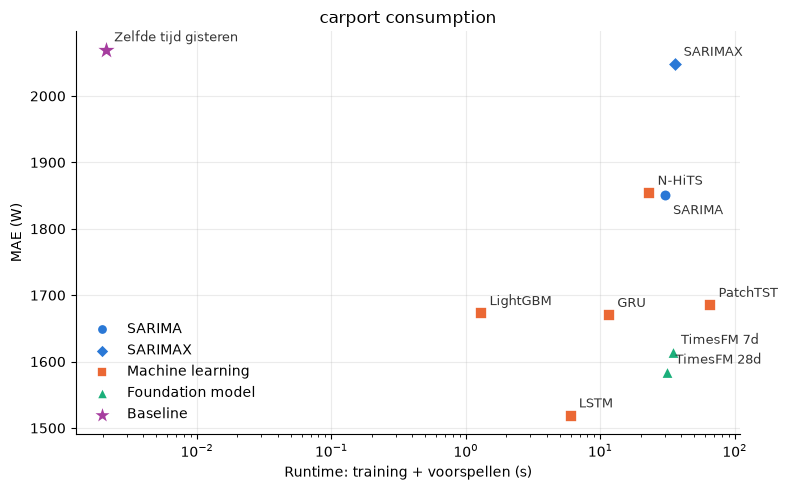

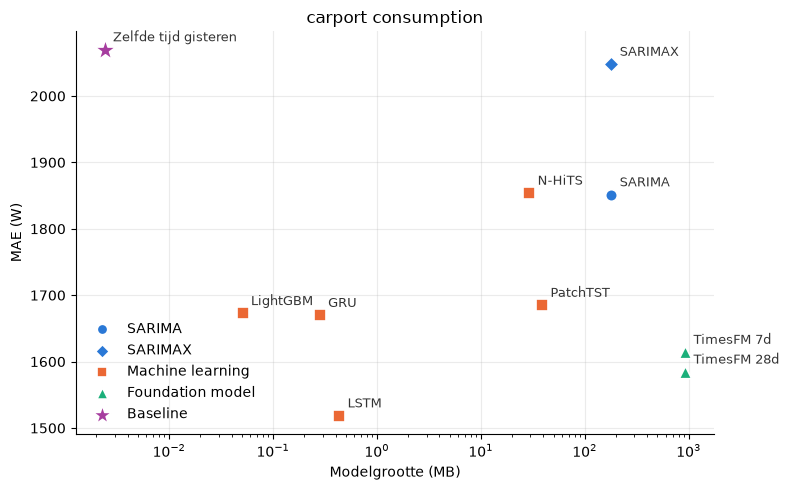

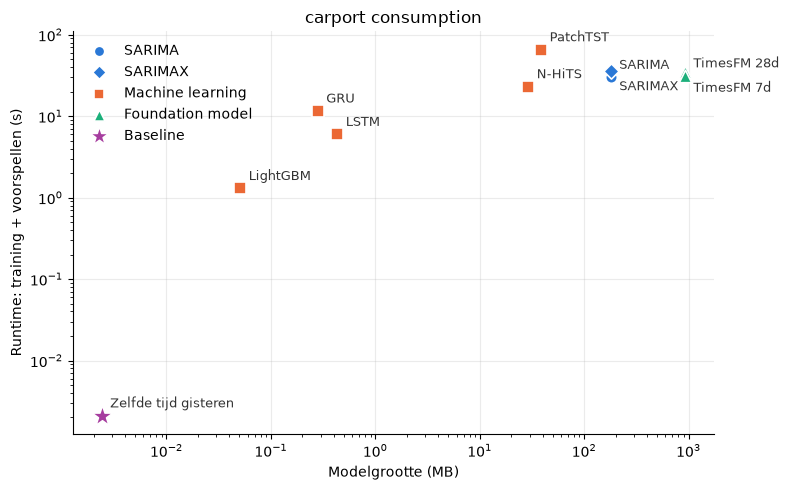

In [15]:
plot_2d("consumption", "runtime (s)", MAE_KOLOM)
plot_2d("consumption", "modelgrootte (MB)", MAE_KOLOM)
plot_2d("consumption", "modelgrootte (MB)", "runtime (s)")

#### Generation

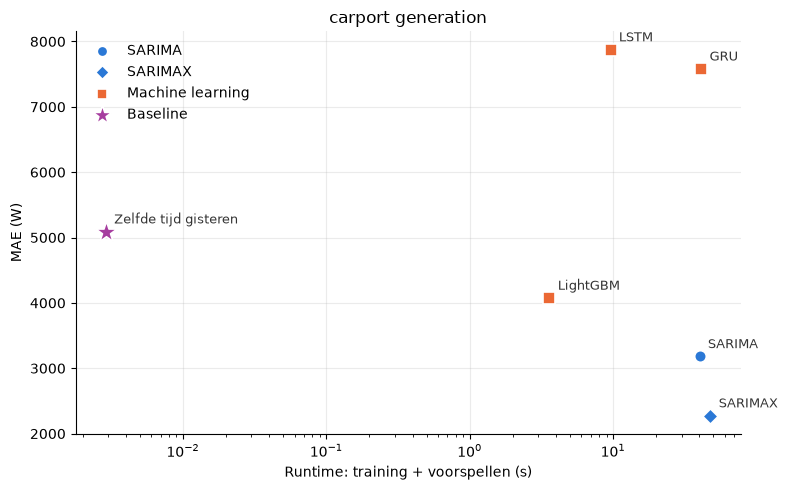

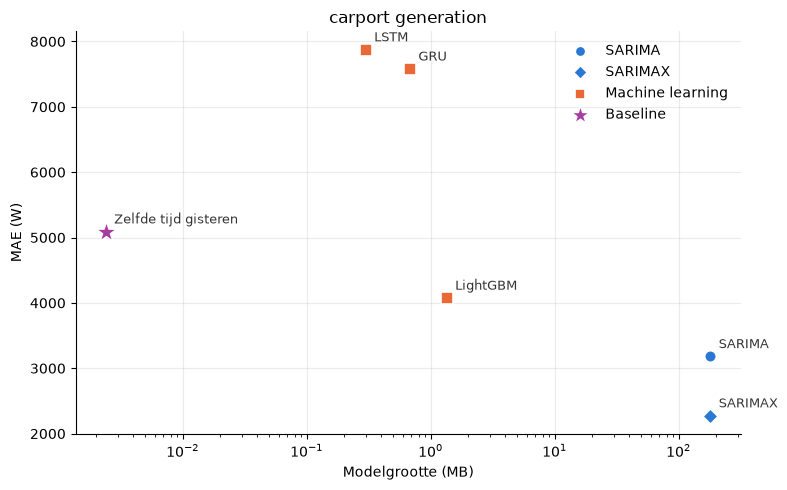

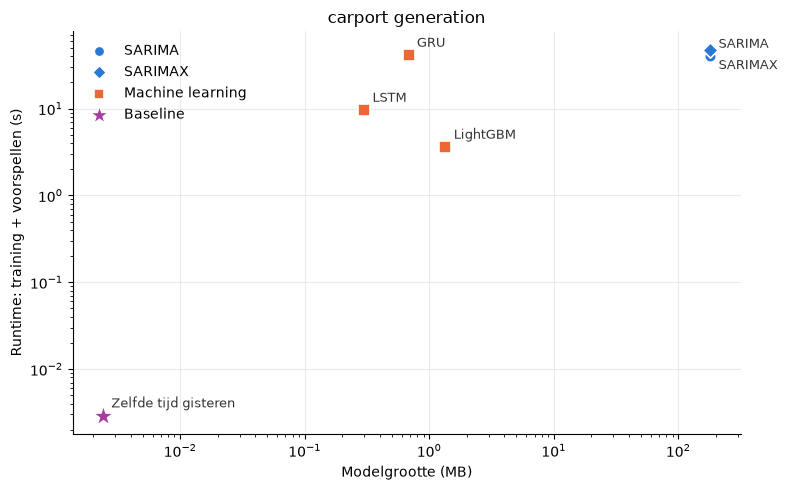

In [16]:
plot_2d("generation", "runtime (s)", MAE_KOLOM)
plot_2d("generation", "modelgrootte (MB)", MAE_KOLOM)
plot_2d("generation", "modelgrootte (MB)", "runtime (s)")